# Lab2 : Linea models and SVM

## Part A — Data and toolkit

%pip install scikit-learn

### PART A.1: 

In [2]:
import numpy as np
import pandas as pd 
from sklearn.metrics import accuracy_score as sk_accuracy_score
from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.datasets import (load_diabetes, load_breast_cancer, load_digits, load_iris)

from sklearn.model_selection import train_test_split 

from sklearn.metrics import (mean_squared_error, r2_score, 
accuracy_score, confusion_matrix as sk_confusion_matrix, precision_recall_fscore_support)

np.set_printoptions(precision=6, suppress=True)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("libraries loaded successfully")

libraries loaded successfully


### load the datasets

In [3]:
diabetes = load_diabetes(scaled=False)
breast_cancer = load_breast_cancer()
digits = load_digits()
iris = load_iris()

datasets = {
    "Diabetes": {
        "X": diabetes.data,
        "y": diabetes.target,
        "feature_names": diabetes.feature_names,
        "task": "regression"
    },

    "Breast Cancer": {
        "X": breast_cancer.data,
        "y": 1 - breast_cancer.target,
        "feature_names": breast_cancer.feature_names,
        "task": "classification"
    },

    "Digits": {
        "X": digits.data / 16.0,
        "y": digits.target,
        "feature_names": [f"pixel_{i}" for i in range(64)],
        "task": "classification"
    },

    "Iris": {
        "X": iris.data,
        "y": iris.target,
        "feature_names": iris.feature_names,
        "task": "classification"
    }
}

for name, data in datasets.items():
    print(
        f"{name}: X = {data['X'].shape}, "
        f"y = {data['y'].shape}"
    )

Diabetes: X = (442, 10), y = (442,)
Breast Cancer: X = (569, 30), y = (569,)
Digits: X = (1797, 64), y = (1797,)
Iris: X = (150, 4), y = (150,)


In [4]:
def split_dataset(X, y, task):
    if task == "classification":
        stratified = y
    else:
        stratified = None

    # First split : 80% training + validation, 20% testing
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=stratified
    )

    stratified_trained = y_train if task == "classification" else None

    # Second split : 75% training, 25% validation
    X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=stratified_trained     
)
    return {"X_train": X_train, "X_val": X_val, "X_test": X_test,
             "y_train": y_train, "y_val": y_val, "y_test": y_test}

In [5]:
# apply the split_dataset function to each dataset
splits = {}
for name, data in datasets.items():
    splits[name] = split_dataset(data["X"], data["y"], data["task"])
    print(f"{name} dataset split into train, validation, and test sets.")

    for split_name in ["train", "val", "test"]:
        X_split = splits[name][f"X_{split_name}"]
        y_split = splits[name][f"y_{split_name}"]
        print(f"{split_name.capitalize()} size : {len(y_split)}")

        if data["task"] == "classification":
            classes, counts = np.unique(y_split, return_counts=True)
            print("class counts:", dict(zip(classes, counts)))

Diabetes dataset split into train, validation, and test sets.
Train size : 264
Val size : 89
Test size : 89
Breast Cancer dataset split into train, validation, and test sets.
Train size : 341
class counts: {np.int64(0): np.int64(214), np.int64(1): np.int64(127)}
Val size : 114
class counts: {np.int64(0): np.int64(71), np.int64(1): np.int64(43)}
Test size : 114
class counts: {np.int64(0): np.int64(72), np.int64(1): np.int64(42)}
Digits dataset split into train, validation, and test sets.
Train size : 1077
class counts: {np.int64(0): np.int64(106), np.int64(1): np.int64(109), np.int64(2): np.int64(107), np.int64(3): np.int64(109), np.int64(4): np.int64(109), np.int64(5): np.int64(109), np.int64(6): np.int64(109), np.int64(7): np.int64(107), np.int64(8): np.int64(104), np.int64(9): np.int64(108)}
Val size : 360
class counts: {np.int64(0): np.int64(36), np.int64(1): np.int64(37), np.int64(2): np.int64(35), np.int64(3): np.int64(37), np.int64(4): np.int64(36), np.int64(5): np.int64(36), np.

### PART A.2 :
Implement a Standardizer (fit, transform; σ = 0 → 1) and add_bias(X). Verify that standardized training 
columns have mean 0 (|mean| < 1e-9) and std 1, while validation and test columns generally do not. In two 
sentences: why must μ and σ come from the training rows only, and how would computing them on all rows 
make your test result misleading? 

In [6]:
class Standardizer:
    def fit (self, X):
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)

        # Avoid division by zero for features with zero variance
        self.std_[self.std_ == 0] = 1.0

        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_
    

In [7]:
# Implement bias
def add_bias(X):
    # Add a column of ones to the input data X to account for the bias term in linear models
    return np.hstack([np.ones((X.shape[0], 1)), X])


In [8]:
# apply standardization to each dataset
standardizers = {}
prepared_datasets = {}
for name, data in datasets.items():
    current_split = splits[name]

    if name == "Digits":
        prepared_datasets[name] = current_split.copy()

        continue
    scaler = Standardizer()
    X_train = scaler.fit(current_split["X_train"]).transform(current_split["X_train"])
    X_test = scaler.transform(current_split["X_test"])
    standardizers[name] = scaler

    prepared_datasets[name] = {
        "X_train": X_train, 
        "X_val": scaler.transform(current_split["X_val"]),
        "X_test": X_test,
        "y_train": current_split["y_train"],
        "y_val": current_split["y_val"],
        "y_test": current_split["y_test"]
    }

print("standardized datasets prepared successfully")

standardized datasets prepared successfully


In [9]:
# verifying standardization
for name in ["Diabetes", "Breast Cancer", "Iris"]:

    X_train = prepared_datasets[name]["X_train"]
    X_val = prepared_datasets[name]["X_val"]
    X_test = prepared_datasets[name]["X_test"]

    train_mean = np.mean(X_train, axis=0)
    train_std = np.std(X_train, axis=0)

    val_mean = np.mean(X_val, axis=0)
    test_mean = np.mean(X_test, axis=0)

    print(f"\n{name}")
    print("-" * 40)

    print("Maximum absolute training mean:",np.max(np.abs(train_mean)))

    print("Maximum training std difference from 1:",np.max(np.abs(train_std - 1)))

    print("Maximum absolute validation mean:",np.max(np.abs(val_mean)))

    print("Maximum absolute test mean:",np.max(np.abs(test_mean)))

    assert np.allclose(train_mean, 0, atol=1e-9)
    assert np.allclose(train_std, 1, atol=1e-9)

print("\nAll standardization checks passed.")


Diabetes
----------------------------------------
Maximum absolute training mean: 2.2372676102294822e-15
Maximum training std difference from 1: 2.1094237467877974e-15
Maximum absolute validation mean: 0.2211148462738231
Maximum absolute test mean: 0.2546242227642893

Breast Cancer
----------------------------------------
Maximum absolute training mean: 5.108979384873301e-15
Maximum training std difference from 1: 8.881784197001252e-16
Maximum absolute validation mean: 0.1325879750576363
Maximum absolute test mean: 0.23245516978615485

Iris
----------------------------------------
Maximum absolute training mean: 1.2927930331190711e-15
Maximum training std difference from 1: 4.440892098500626e-16
Maximum absolute validation mean: 0.33818222886043636
Maximum absolute test mean: 0.1932469879202495

All standardization checks passed.


The mean and standard deviation must be calculated using only the training data to prevent data leakage and ensure that the model does not gain information from unseen data. If statistics are calculated using all datasets, information from the test set influences preprocessing, making the final test performance misleadingly optimistic.

### Part A.3 :
implement mse, rmse, r2, accuracy, confusion_matrix(y, pred, K) (rows = true class, columns = 
predicted class), and per-class precision, recall and F1 from the confusion matrix plus their macro averages. 
Define precision = 0 for a class that is never predicted, and say so in a comment. Check everything against 
sklearn.metrics on random labels (K = 4, N = 500) to 1e-12. 

In [10]:
# regression metrics
def mean_squared_error(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean((y_true - y_pred) ** 2)

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def mean_absolute_error(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def r2_score(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# classification metrics
def accuracy_score(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred , K):
    y = np.asarray (y_true, dtype=int)
    y_hat = np.asarray (y_pred, dtype=int)
    cm = np.zeros((K, K), dtype=int)

    np.add.at(cm, (y, y_hat), 1)
    return cm


def classification_metrics(cm):
    # true positive
    tp = np.diag(cm)
    # predicted counts : sum of each column
    predicted_counts = np.sum(cm, axis=0)
    # actual counts : sum of each row
    actual_counts = np.sum(cm, axis=1)
    # precision = 0 when predicted counts = 0
    precision = np.divide(tp, predicted_counts, out=np.zeros_like(tp, dtype=float), where=predicted_counts != 0)
    # recall = 0 when actual counts = 0
    recall = np.divide(tp, actual_counts, out=np.zeros_like(tp, dtype=float), where=actual_counts != 0)
    # f1_score = 0 when precision or recall = 0
    f1_score = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(tp, dtype=float), where=precision + recall != 0)

    return {
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "macros_precision": np.mean(precision),
        "macros_recall": np.mean(recall),
        "macros_f1_score": np.mean(f1_score)
    }


In [11]:
# ----- AI ASSISTANT PART ------
from sklearn.metrics import (mean_squared_error as sk_mean_squared_error, r2_score as sk_r2_score, 
                             accuracy_score as sk_accuracy_score, confusion_matrix as sk_confusion_matrix,
                             precision_recall_fscore_support)
# faced some errors so I added what AI suggested for me.
# Verify the regression metrics implementation
check_rng = np.random.default_rng(RANDOM_STATE)

y_regression_true = check_rng.normal(size=500)
y_regression_pred = check_rng.normal(size=500)

# Our implementations
custom_mse = mean_squared_error(y_regression_true, y_regression_pred)
custom_rmse = np.sqrt(custom_mse)
custom_r2 = r2_score(y_regression_true, y_regression_pred)

# sklearn reference values
sk_mse = sk_mean_squared_error(y_regression_true, y_regression_pred)
sk_rmse = np.sqrt(sk_mse)
sk_r2 = sk_r2_score(y_regression_true, y_regression_pred)

# Compare regression metrics
assert np.isclose(custom_mse, sk_mse, atol=1e-12, rtol=0)
assert np.isclose(custom_rmse, sk_rmse, atol=1e-12, rtol=0)
assert np.isclose(custom_r2, sk_r2, atol=1e-12, rtol=0)


# Verify the classification metrics implementation
K = 4
N = 500

y_classification_true = check_rng.integers(0, K, size=N)
y_classification_pred = check_rng.integers(0, K, size=N)

# Our implementations
custom_accuracy = accuracy_score(y_classification_true,y_classification_pred)

cm = confusion_matrix(y_classification_true,y_classification_pred,K)


metrics = classification_metrics(cm)

# sklearn reference values
sk_cm = sk_confusion_matrix(y_classification_true,y_classification_pred,labels=np.arange(K))

sk_precision, sk_recall, sk_f1_score, _ = precision_recall_fscore_support(
    y_classification_true,
    y_classification_pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

sk_accuracy = sk_accuracy_score(y_classification_true,y_classification_pred)

# Compare confusion matrices
assert np.array_equal(cm, sk_cm)

# Compare accuracy
assert np.isclose(custom_accuracy,sk_accuracy,atol=1e-12,rtol=0)

# Compare per-class metrics
assert np.allclose(metrics["precision"],sk_precision,atol=1e-12,rtol=0)

assert np.allclose(metrics["recall"],sk_recall,atol=1e-12,rtol=0)

assert np.allclose(metrics["f1_score"],sk_f1_score,atol=1e-12,rtol=0)

# Compare macro averages
assert np.isclose(
    metrics["macros_precision"],
    np.mean(sk_precision),
    atol=1e-12,
    rtol=0
)

assert np.isclose(
    metrics["macros_recall"],
    np.mean(sk_recall),
    atol=1e-12,
    rtol=0
)

assert np.isclose(
    metrics["macros_f1_score"],
    np.mean(sk_f1_score),
    atol=1e-12,
    rtol=0
)

print("All regression and classification metrics checks passed successfully!")

print("\nConfusion Matrix:\n", cm)
print("\nAccuracy:", custom_accuracy)
print("Precision:", metrics["precision"])
print("Recall:", metrics["recall"])
print("F1 Score:", metrics["f1_score"])

print("\nMacro Precision:", metrics["macros_precision"])
print("Macro Recall:", metrics["macros_recall"])
print("Macro F1 Score:", metrics["macros_f1_score"])


All regression and classification metrics checks passed successfully!

Confusion Matrix:
 [[29 32 36 33]
 [31 36 36 36]
 [33 21 20 33]
 [33 29 30 32]]

Accuracy: 0.234
Precision: [0.230159 0.305085 0.163934 0.238806]
Recall: [0.223077 0.258993 0.186916 0.258065]
F1 Score: [0.226562 0.280156 0.174672 0.248062]

Macro Precision: 0.234495968075051
Macro Recall: 0.2317625332029546
Macro F1 Score: 0.23236316165254792


### Part A.4 :
grad_check(f, grad, w) following the protocol of Section 5; it returns the relative error, and you will call it 
in every later Part. 

In [12]:
# gradient checking function
def grad_check(f, grad, w, epsilon=1e-5, num_checks=None, rng=None):
   w = np.asarray(w, dtype=float)

   # Analytical gradient 
   analytical_grad = np.asarray(grad(w), dtype=float)

   # check the gradient has the same shape as w
   assert analytical_grad.shape == w.shape

   # select entries to check
   if num_checks is None or num_checks > w.size :
      indices = np.arange(w.size)
   else:
      if rng is None:
         rng = np.random.default_rng(42)
      indices = rng.choice(w.size, size=num_checks, replace=False)
   numerical_grad = np.zeros_like(w)


   # numerical gradient using central difference
   for i in indices:
        w_plus = np.copy(w)
        w_minus = np.copy(w)
        w_plus[i] += epsilon
        w_minus[i] -= epsilon
        numerical_grad.flat[i] = (f(w_plus) - f(w_minus)) / (2 * epsilon)

    # compare only the selected entries
   analytical_values = analytical_grad.flat[indices]
   numerical_values = numerical_grad.flat[indices]

   numerator = np.linalg.norm(analytical_values - numerical_values)
   denominator = max(np.linalg.norm(analytical_values), np.linalg.norm(numerical_values), 1e-12)
   relative_error = numerator / denominator

   return relative_error
    

In [13]:

# Test the gradient checker using a simple quadratic function

def test_function(w):
    return 0.5 * np.sum(w ** 2)


def test_gradient(w):
    return w


# Generate a random point from N(0, 0.1^2)
gradient_rng = np.random.default_rng(42)

w_check = gradient_rng.normal(loc=0.0,scale=0.1,size=10)

error = grad_check(test_function,test_gradient,w_check,epsilon=1e-5)

print("Gradient checking relative error:", error)

assert error < 1e-6

print("Gradient checker passed!")


Gradient checking relative error: 2.412402124885373e-12
Gradient checker passed!


# PART B :
Dataset: Diabetes, features standardized with training statistics, target left in its original units. Model ŷ = X̃w, J(w) = 
(1/2N)‖X̃w − y‖². 
### PART B.1 :
Closed form. Derive the normal equations from ∇J = 0 (show the steps) and implement normal_equation(X, 
y) with np.linalg.solve on X̃ᵀX̃ — not np.linalg.inv.
– Report the weights in a table with feature names, train / validation / test RMSE, test R² and cond(X̃ᵀX̃). 
– Verify: your weights match LinearRegression (fit on the same standardized data) to within 1e-6. 
– Sanity: test R² between 0.40 and 0.50; condition number in the hundreds. – In three sentences: compare the signs and sizes of the weights of s1, s2 and bmi. Why is interpreting 
individual weights risky when features are correlated? 

In [14]:
def normal_equation(X, y):
    # Add bias term to the input data X
    X_b = add_bias(X)
    
    A = X_b.T @ X_b  # Compute the matrix A = X^T * X
    b = X_b.T @ y    # Compute the vector b = X^T * y
    
    # Solve the linear system Aw = b
    w = np.linalg.solve(A, b)
    
    return w

In [15]:
# predictions and RMSE calculation

diabetes_split = prepared_datasets["Diabetes"]
X_train = diabetes_split["X_train"]
X_val = diabetes_split["X_val"]
X_test = diabetes_split["X_test"]
y_train = diabetes_split["y_train"]
y_val = diabetes_split["y_val"]
y_test = diabetes_split["y_test"]

X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)


W = normal_equation(X_train, y_train)

train_predictions = X_train_bias @ W
val_predictions = X_val_bias @ W
test_predictions = X_test_bias @ W

train_rmse = root_mean_squared_error(y_train, train_predictions)
val_rmse = root_mean_squared_error(y_val, val_predictions)
test_rmse = root_mean_squared_error(y_test, test_predictions)

test_r2 = r2_score(y_test, test_predictions)



In [16]:
condition_number = np.linalg.cond(X_train_bias.T @ X_train_bias)

feature_names = ["bias"] + list(datasets["Diabetes"]["feature_names"])

weight_table = pd.DataFrame({"Feature": feature_names,"Weight": W})

print("Learned Weights:")
display(weight_table)

performance_table = pd.DataFrame({
    "Metric": [
        "Train RMSE",
        "Validation RMSE",
        "Test RMSE",
        "Test R2",
        "Condition Number"
    ],
    "Value": [
        train_rmse,
        val_rmse,
        test_rmse,
        test_r2,
        condition_number
    ]
})

print("Model Performance:")
display(performance_table)

Learned Weights:


,Feature,Weight
0,bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


Model Performance:


,Metric,Value
0,Train RMSE,54.610364
1,Validation RMSE,51.193714
2,Test RMSE,54.156413
3,Test R2,0.446426
4,Condition Number,505.706123


In [17]:
sk_model = LinearRegression()
sk_model.fit(X_train, y_train)

sk_weights = np.concatenate(([sk_model.intercept_], sk_model.coef_))

assert np.allclose(W, sk_weights, atol=1e-6, rtol=0)
print("Normal Equation matches sklearn LinearRegression!")

Normal Equation matches sklearn LinearRegression!


The BMI feature has a positive coefficient of approximately 25.08, while s1 has a negative coefficient of approximately -51.10, and s2 has a positive coefficient of approximately 27.48. The absolute value of the s1 coefficient is larger than those of BMI and s2. However, interpreting individual coefficients can be risky because correlated features may share information, making their estimated coefficients sensitive to changes in the data.

### PART B.2:
Gradient descent. Implement batch GD from w = 0 and measure progress by the relative distance ‖w − 
w*‖/‖w*‖, where w* is your Task 5 solution. 
– (a) Run 2000 epochs for each η ∈ {0.001, 0.01, 0.1, 0.5, 1.0}. Plot J against epoch (log y-axis) for all runs 
on one figure, and tabulate the final J, the final relative distance, and the first epoch at which the 
distance drops below 1e-3 (or “not reached”). 
– (b) Compute λₘₐₓ, the largest eigenvalue of H = X̃ᵀX̃/N. Show experimentally that η = 0.95·(2/λₘₐₓ) 
converges while η = 1.05·(2/λₘₐₓ) diverges, and derive why 2/λₘₐₓ is the threshold from e(t+1) = (I − 
ηH)e(t). 
– Sanity: exactly one of the five learning rates diverges, and exactly one reaches 1e-3 within 2000 epochs.

In [18]:
def batch_gradient_descent(X, y, W, learning_rate=0.01, epochs=2000):
    N = X.shape[0]
    w = np.zeros(X.shape[1])

    losses = []
    distances = []
    for epoch in range(epochs):
        # Compute predictions
        predictions = X @ w
        
        # Compute the gradient
        gradient = (1 / N) * (X.T @ (predictions - y))
        
        # Update weights
        w -= learning_rate * gradient
        
        # Calculate loss (MSE)
        updated_predictions = X @ w
        loss = 0.5 * mean_squared_error(y, updated_predictions)
        losses.append(loss)
        
        # Calculate distance to the optimal weights
        distance = np.linalg.norm(w - W)/np.linalg.norm(W)
        distances.append(distance)

    return w, np.array(losses), np.array(distances)

In [19]:
# run the 5 learning rates
learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]

gd_results = {}
for lr in learning_rates:
    w_gd, losses, distances = batch_gradient_descent(X_train_bias, y_train, W, learning_rate=lr, epochs=2000)
    gd_results[lr] = {
        "weights": w_gd,
        "losses": losses,
        "distances": distances
    }

c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\3539949200.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred) ** 2)
c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\linalg\_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\1611338114.py:12: RuntimeWarning: overflow encountered in matmul
  gradient = (1 / N) * (X.T @ (predictions - y))
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\1611338114.py:18: RuntimeWarning: invalid value encountered in matmul
  updated_predictions = X @ w
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\1611338114.py:9: RuntimeWarning: invalid value encountered in matmul
  pr

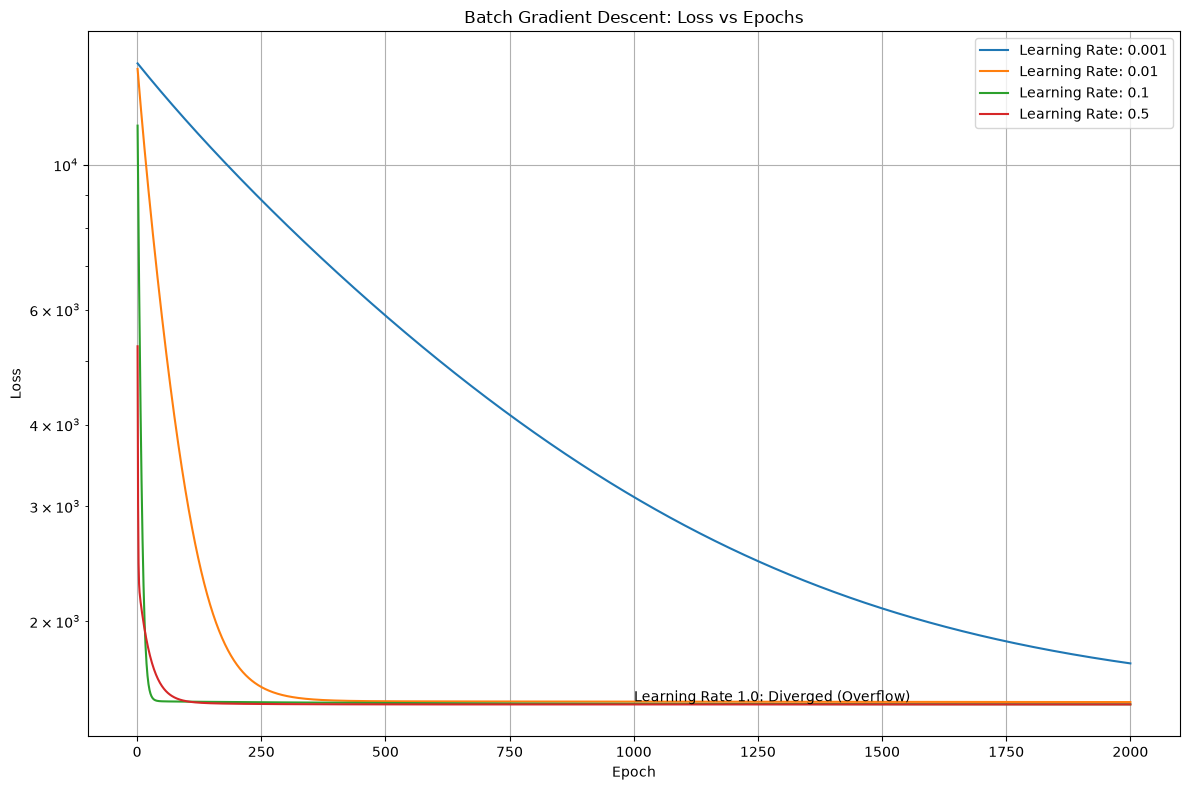

In [20]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 8))

for lr in [0.001, 0.01, 0.1, 0.5]:
    losses = gd_results[lr]["losses"]

    epochs = np.arange(1, len(losses) + 1)

    valid = np.isfinite(losses) & (losses > 0)

    plt.plot(epochs[valid], losses[valid], label=f"Learning Rate: {lr}")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.yscale("log")
plt.title("Batch Gradient Descent: Loss vs Epochs")

plt.text(0.5, 0.05, "Learning Rate 1.0: Diverged (Overflow)", transform=plt.gca().transAxes)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
results = []

for lr in learning_rates:
    losses = gd_results[lr]["losses"]
    distances = gd_results[lr]["distances"]

    reached = np.where(distances < 1e-3)[0]

    first_reached_epoch = (reached[0] + 1 if len(reached) > 0 else "not reached")

    results.append({
        "learning_rate": lr,
        "final_loss": losses[-1],
        "final_distance": distances[-1],
        "first_reached_epoch": first_reached_epoch
    })

results_df = pd.DataFrame(results)
display(results_df)

,learning_rate,final_loss,final_distance,first_reached_epoch
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,NaN,NaN,not reached


In [22]:
#Compute λₘₐₓ, the largest eigenvalue of H = X̃ᵀX̃/N 

N = X_train_bias.shape[0]
H = (X_train_bias.T @ X_train_bias) / N

# calculate the largest eigenvalue of H
eigenvalue = np.linalg.eigvalsh(H)
lambda_max = np.max(eigenvalue)

# calculating critical rate
# eta(threshold) = 2/λₘₐₓ
#η = 0.95·(2/λₘₐₓ) converges and η = 1.05·(2/λₘₐₓ) diverges

eta = 2 / lambda_max
eta_converges = 0.95 * eta
eta_diverges = 1.05 * eta

print("Lambda max: ",lambda_max)
print("Threshold: ", eta)
print("converges: ",eta_converges)
print("diverges:", eta_diverges)

Lambda max:  3.954755032050376
Threshold:  0.5057203249737274
converges:  0.48043430872504106
diverges: 0.5310063412224139


In [23]:
w_converges, losses_converges, distances_converges = batch_gradient_descent(X_train_bias, y_train,
                                                                             W, learning_rate=eta_converges, epochs=2000)
w_diverges, losses_diverges, distances_diverges = batch_gradient_descent(X_train_bias, y_train,
                                                                          W, learning_rate=eta_diverges, epochs=2000)

print("Converges final distance:", distances_converges[-1])
print("Diverges final distance:", distances_diverges[-1])


Converges final distance: 0.00021023075314223705
Diverges final distance: 7.581863342433945e+81


In [24]:
# Task 7: Why scaling matters

#get the original, unstandardized Diabetes training features
X_train_raw = splits["Diabetes"]["X_train"]
y_train_raw = splits["Diabetes"]["y_train"]

#add the bias column
X_train_raw_bias = add_bias(X_train_raw)

#get the standardized training features from Task 5/6
X_train_standardized = prepared_datasets["Diabetes"]["X_train"]
X_train_standardized_bias = add_bias(X_train_standardized)

print("Raw features shape:", X_train_raw_bias.shape)
print("Standardized features shape:", X_train_standardized_bias.shape)

print("\nRaw feature standard deviations:")
print(np.std(X_train_raw, axis=0))

print("\nStandardized feature standard deviations:")
print(np.std(X_train_standardized, axis=0))

Raw features shape: (264, 11)
Standardized features shape: (264, 11)

Raw feature standard deviations:
[12.74507   0.499871  4.374058 14.007533 35.22319  31.242438 12.280194
  1.271273  0.501466 11.400465]

Standardized feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [25]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:

# Task 7: Calculate condition number and learning rate limit

#calculate H = X^T X / N for raw features
N_raw = X_train_raw_bias.shape[0]
H_raw = (X_train_raw_bias.T @ X_train_raw_bias) / N_raw

#calculate H for standardized features
N_std = X_train_standardized_bias.shape[0]
H_std = (X_train_standardized_bias.T @ X_train_standardized_bias) / N_std

#condition numbers
cond_raw = np.linalg.cond(X_train_raw_bias.T @ X_train_raw_bias)
cond_std = np.linalg.cond(X_train_standardized_bias.T @ X_train_standardized_bias)

#largest eigenvalues
lambda_max_raw = np.linalg.eigvalsh(H_raw)[-1]
lambda_max_std = np.linalg.eigvalsh(H_std)[-1]

#maximum learning rate limits
eta_limit_raw = 2 / lambda_max_raw
eta_limit_std = 2 / lambda_max_std

#print results
print("Raw features:")
print("Condition number:", cond_raw)
print("2 / lambda_max:", eta_limit_raw)

print("\nStandardized features:")
print("Condition number:", cond_std)
print("2 / lambda_max:", eta_limit_std)


Raw features:
Condition number: 55778473.21647313
2 / lambda_max: 2.7427928748390996e-05

Standardized features:
Condition number: 505.706122696069
2 / lambda_max: 0.5057203249737274


c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\3539949200.py:5: RuntimeWarning: overflow encountered in square
  return np.mean((y_true - y_pred) ** 2)
c:\Users\Mega Store\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\linalg\_linalg.py:2767: RuntimeWarning: overflow encountered in dot
  sqnorm = x.dot(x)
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\1611338114.py:12: RuntimeWarning: overflow encountered in matmul
  gradient = (1 / N) * (X.T @ (predictions - y))
C:\Users\Mega Store\AppData\Local\Temp\ipykernel_20568\1611338114.py:15: RuntimeWarning: invalid value encountered in subtract
  w -= learning_rate * gradient


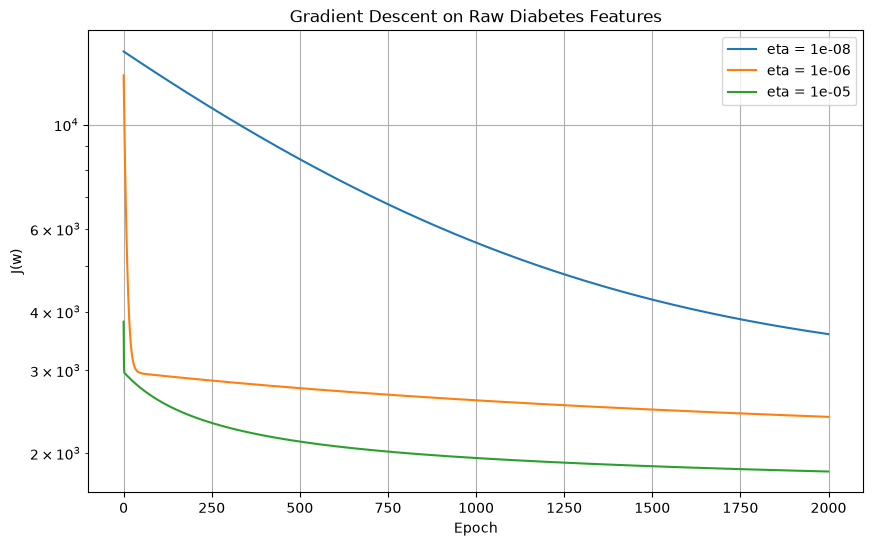

Learning Rate | Final J | Final Relative Distance | First Epoch < 1e-3
1e-08          | 3584       | 1                        | Not reached
1e-06          | 2389       | 1                        | Not reached
1e-05          | 1828       | 0.9998                   | Not reached
0.0001         | nan        | nan                      | Not reached


In [27]:

# Task 7: Gradient Descent on raw features

#calculate the optimal weights using raw features
w_star_raw = np.linalg.solve(
    X_train_raw_bias.T @ X_train_raw_bias,
    X_train_raw_bias.T @ y_train_raw
)

#learning rates required in task7
learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]

raw_results = {}

#run gradient descent for each learning rate
for eta in learning_rates:
    w, losses, distances = batch_gradient_descent(
        X_train_raw_bias,
        y_train_raw,
        w_star_raw,
        learning_rate=eta,
        epochs=2000
    )

    raw_results[eta] = {
        "weights": w,
        "losses": losses,
        "distances": distances
    }

#plot loss against epoch for stable learning rates only
plt.figure(figsize=(10, 6))

for eta in [1e-8, 1e-6, 1e-5]:
    plt.plot(
        raw_results[eta]["losses"],
        label=f"eta = {eta}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("J(w)")
plt.title("Gradient Descent on Raw Diabetes Features")
plt.legend()
plt.grid(True)
plt.show()

#print results table
print("Learning Rate | Final J | Final Relative Distance | First Epoch < 1e-3")

for eta in learning_rates:
    losses = raw_results[eta]["losses"]
    distances = raw_results[eta]["distances"]

    reached = np.where(distances < 1e-3)[0]

    first_epoch = reached[0] + 1 if len(reached) > 0 else "Not reached"

    print(
        f"{eta:<14} | "
        f"{losses[-1]:<10.4g} | "
        f"{distances[-1]:<24.4g} | "
        f"{first_epoch}"
    )
    


<--with the help of AI-->

The condition number is much higher for raw features (about 55.8 million) than standardized features (about 506). This means that raw features need a much smaller learning rate to keep gradient descent stable. Because of the small learning rates, gradient descent is very slow and does not reach the optimal solution within 2000 epochs. Standardization makes gradient descent faster, while η = 1e-4 causes divergence on raw features.

### PART B.3: Stochastic and Mini-Batch Gradient Descent

In [28]:

def mini_batch_gradient_descent(X, y, learning_rate=0.01,
                                epochs=100, batch_size=16):

    N = X.shape[0]
    w = np.zeros(X.shape[1]) #kol weight ykon b zero at beg

    losses = []
    updates = []

    update_count = 0

    rng = np.random.default_rng(42)

    for epoch in range(epochs):

        # Shuffle training data every epoch
        indices = rng.permutation(N)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        # Divide data into mini-batches
        for start in range(0, N, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            B = len(y_batch)

            # Calculate predictions
            predictions = X_batch @ w

            # Calculate gradient
            gradient = (X_batch.T @ (predictions - y_batch)) / B

            # Update weights
            w -= learning_rate * gradient

            update_count += 1

        # Calculate loss using training set
        full_predictions = X @ w

        loss = 0.5 * mean_squared_error(y, full_predictions)

        losses.append(loss)
        updates.append(update_count)

    return w, np.array(losses), np.array(updates)


#### Compare Different Batch Sizes

In [29]:

batch_sizes = [1, 16, 64, len(y_train)]

batch_results = {}

for B in batch_sizes:

    w, losses, updates = mini_batch_gradient_descent(
        X_train_bias,
        y_train,
        learning_rate=0.01,
        epochs=100,
        batch_size=B
    )

    batch_results[B] = {
        "weights": w,
        "losses": losses,
        "updates": updates
    }

    print("Batch size:", B)
    print("Final loss:", losses[-1])
    print("Total updates:", updates[-1])
    print("-" * 40)


Batch size: 1
Final loss: 1534.8083853086
Total updates: 26400
----------------------------------------
Batch size: 16
Final loss: 1505.665099007747
Total updates: 1700
----------------------------------------
Batch size: 64
Final loss: 1511.3753357143576
Total updates: 500
----------------------------------------
Batch size: 264
Final loss: 3085.440478999073
Total updates: 100
----------------------------------------


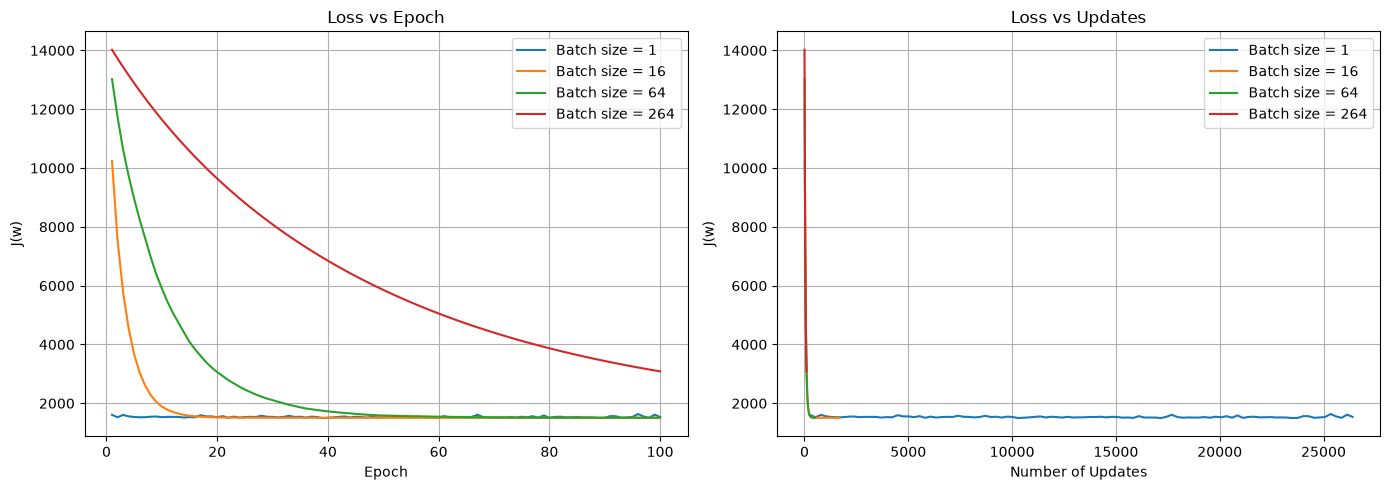

In [30]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:

    losses = batch_results[B]["losses"]
    updates = batch_results[B]["updates"]

    axes[0].plot(
        np.arange(1, 101),
        losses,
        label=f"Batch size = {B}"
    )

    axes[1].plot(
        updates,
        losses,
        label=f"Batch size = {B}"
    )

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("J(w)")
axes[0].set_title("Loss vs Epoch")
axes[0].legend()
axes[0].grid(True)

axes[1].set_xlabel("Number of Updates")
axes[1].set_ylabel("J(w)")
axes[1].set_title("Loss vs Updates")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## SGD with different learning rates

In [31]:


learning_rates = [0.001, 0.01, 0.1]

sgd_results = {}

for eta in learning_rates:

    w, losses, updates = mini_batch_gradient_descent(
        X_train_bias,
        y_train,
        learning_rate=eta,
        epochs=100,
        batch_size=1
    )

    sgd_results[eta] = losses

    print(f"Learning Rate: {eta}")
    print(f"Final Loss: {losses[-1]}")
    print("-" * 30)


Learning Rate: 0.001
Final Loss: 1503.3121768105561
------------------------------
Learning Rate: 0.01
Final Loss: 1534.8083853086
------------------------------
Learning Rate: 0.1
Final Loss: 4186.980951940034
------------------------------


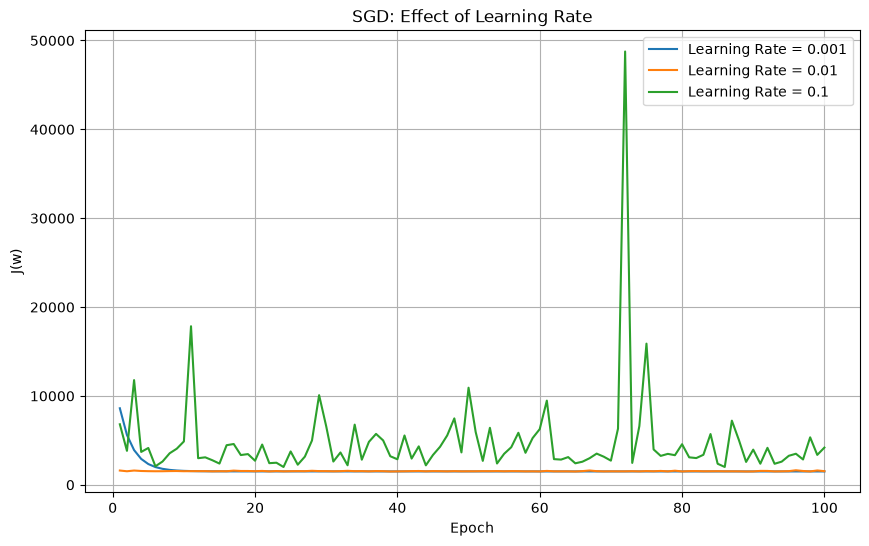

In [32]:

plt.figure(figsize=(10, 6))

for eta in learning_rates:

    plt.plot(
        range(1, 101),
        sgd_results[eta],
        label=f"Learning Rate = {eta}"
    )

plt.xlabel("Epoch")
plt.ylabel("J(w)")
plt.title("SGD: Effect of Learning Rate")
plt.legend()
plt.grid(True)
plt.show()


The batch size affects both the number of updates and the convergence behavior. Smaller batches perform more updates per epoch but produce noisier loss curves, while larger batches produce smoother updates but may require more epochs to converge. In our experiment, batch size 16 achieved the lowest final loss, while full-batch gradient descent converged more slowly.

For SGD, the learning rate strongly affects stability. Learning rates 0.001 and 0.01 produced relatively stable results, while 0.1 caused large fluctuations in the loss, indicating an excessively large learning rate.

### PART B.4 — Task 9: Ridge Regression (L2 Regularization)

Ridge Regression adds an L2 regularization term to the Linear Regression cost function to reduce overfitting and control large coefficients.

The objective function is:

\[
J_\lambda(w)=\frac{1}{2N}\|\tilde Xw-y\|^2+\frac{\lambda}{2}\|w_{1:}\|^2
\]

where:
- \(\lambda\) is the regularization parameter.
- \(w_0\) is the bias and is not penalized.
- \(w_{1:}\) represents all weights except the bias.

#### Ridge Regression: Small Worked Example

In [33]:

X_toy = np.array([[1.0],
                  [2.0],
                  [3.0]])

y_toy = np.array([2.0, 3.0, 5.0])

lam = 1.0

X_toy_bias = add_bias(X_toy)
N_toy = len(y_toy)

I0 = np.eye(X_toy_bias.shape[1])
I0[0, 0] = 0

w_toy = np.linalg.solve(
    (X_toy_bias.T @ X_toy_bias) / N_toy + lam * I0,
    (X_toy_bias.T @ y_toy) / N_toy
)

print("Ridge weights:", w_toy)

Ridge weights: [2.133333 0.6     ]


In [34]:
def ridge_closed_form(X, y, lam):
    X_b = add_bias(X)
    N = X_b.shape[0]

    I0 = np.eye(X_b.shape[1])
    I0[0, 0] = 0

    A = (X_b.T @ X_b) / N + lam * I0
    b = (X_b.T @ y) / N

    w = np.linalg.solve(A, b)

    return w

### Apply Ridge Regression on Diabetes original features

In [35]:
lambda_value = 0.1

w_ridge = ridge_closed_form(X_train, y_train, lambda_value)

print("Ridge weights:")
print(w_ridge)

print("Number of weights:", len(w_ridge))

Ridge weights:
[149.810606   1.715201 -10.272203  24.003127  14.036236  -6.722063
  -5.639887  -8.029795   7.876198  20.082479   4.826142]
Number of weights: 11


In [36]:
# Calculate Ridge predictions

X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)

train_pred_ridge = X_train_bias @ w_ridge
val_pred_ridge = X_val_bias @ w_ridge
test_pred_ridge = X_test_bias @ w_ridge

# Calculate RMSE

train_rmse_ridge = root_mean_squared_error(y_train, train_pred_ridge)
val_rmse_ridge = root_mean_squared_error(y_val, val_pred_ridge)
test_rmse_ridge = root_mean_squared_error(y_test, test_pred_ridge)

print("Ridge Train RMSE:", train_rmse_ridge)
print("Ridge Validation RMSE:", val_rmse_ridge)
print("Ridge Test RMSE:", test_rmse_ridge)

Ridge Train RMSE: 54.98310683251263
Ridge Validation RMSE: 51.207304584010046
Ridge Test RMSE: 53.7089252748126


### Test different lambda values

In [37]:

lambdas = np.concatenate(([0.0], np.logspace(-3, 1, 9)))

ridge_results = {}

for lam in lambdas:
    w = ridge_closed_form(X_train, y_train, lam)

    val_pred = X_val_bias @ w
    test_pred = X_test_bias @ w

    ridge_results[lam] = {
        "weights": w,
        "val_rmse": root_mean_squared_error(y_val, val_pred),
        "test_rmse": root_mean_squared_error(y_test, test_pred)
    }

for lam, result in ridge_results.items():
    print(
        f"Lambda: {lam:.4f} | "
        f"Validation RMSE: {result['val_rmse']:.4f} | "
        f"Test RMSE: {result['test_rmse']:.4f}"
    )

Lambda: 0.0000 | Validation RMSE: 51.1937 | Test RMSE: 54.1564
Lambda: 0.0010 | Validation RMSE: 51.1496 | Test RMSE: 54.1082
Lambda: 0.0032 | Validation RMSE: 51.1080 | Test RMSE: 54.0437
Lambda: 0.0100 | Validation RMSE: 51.1047 | Test RMSE: 53.9585
Lambda: 0.0316 | Validation RMSE: 51.1531 | Test RMSE: 53.8600
Lambda: 0.1000 | Validation RMSE: 51.2073 | Test RMSE: 53.7089
Lambda: 0.3162 | Validation RMSE: 51.5780 | Test RMSE: 53.6724
Lambda: 1.0000 | Validation RMSE: 53.6951 | Test RMSE: 54.8569
Lambda: 3.1623 | Validation RMSE: 59.4203 | Test RMSE: 59.0928
Lambda: 10.0000 | Validation RMSE: 66.9546 | Test RMSE: 65.3039


### Plot Ridge coefficients vs Lambda

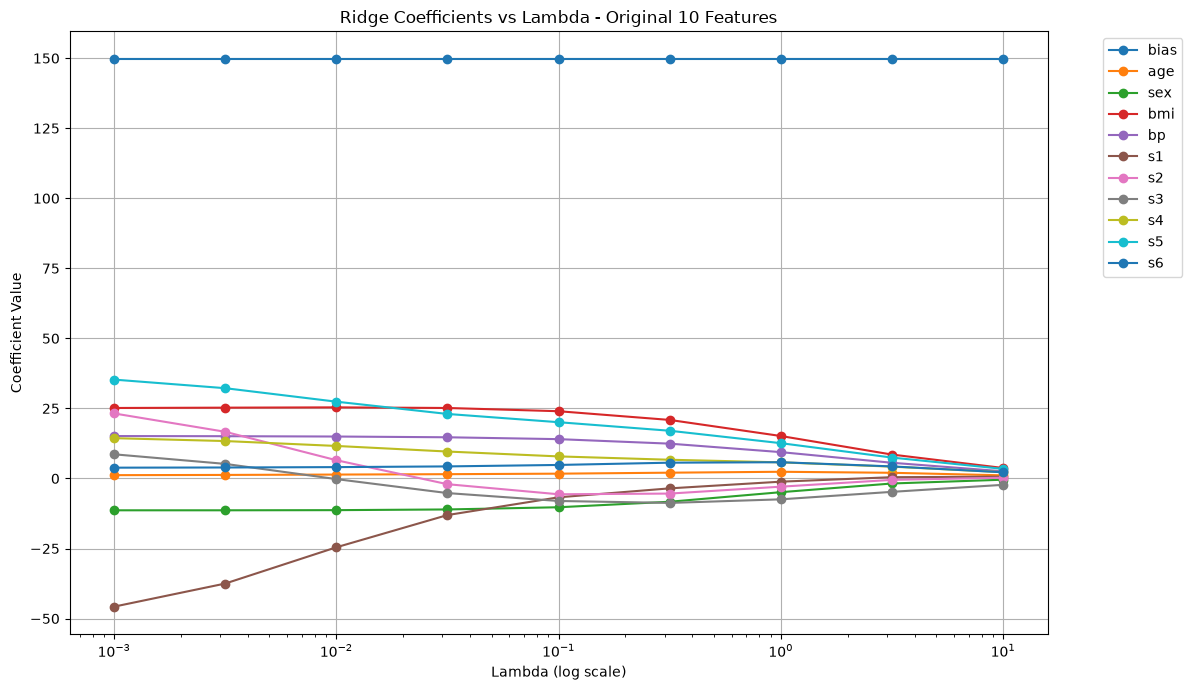

In [38]:
positive_lambdas = lambdas[lambdas > 0]

plt.figure(figsize=(12, 7))

for i, name in enumerate(feature_names):
    coefficients = [
        ridge_results[lam]["weights"][i]
        for lam in positive_lambdas
    ]

    plt.plot(positive_lambdas, coefficients, marker='o', label=name)

plt.xscale("log")
plt.xlabel("Lambda (log scale)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients vs Lambda - Original 10 Features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

### Plot Validation RMSE vs Lambda

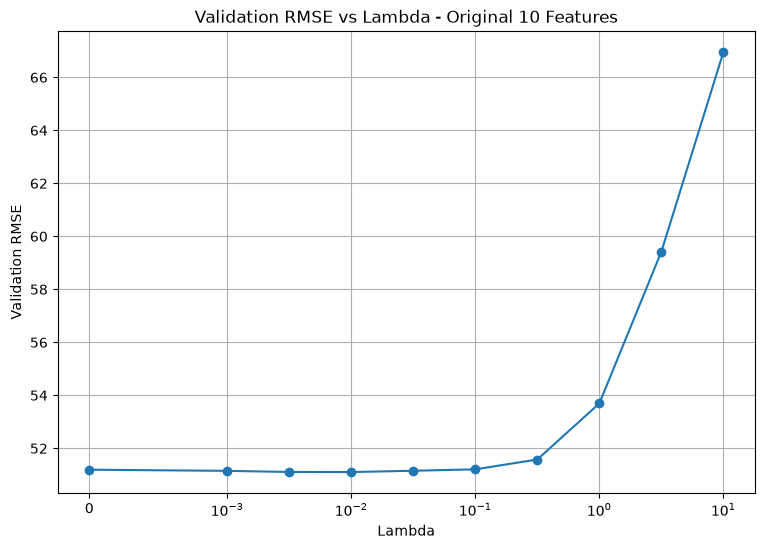

In [39]:
val_errors = [
    ridge_results[lam]["val_rmse"]
    for lam in lambdas
]

plt.figure(figsize=(9, 6))

plt.plot(lambdas, val_errors, marker='o')

plt.xscale("symlog", linthresh=0.001)
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Lambda - Original 10 Features")
plt.grid(True)
plt.show()

In [40]:
def degree2_features(X):
    n, d = X.shape

    columns = [X[:, i] for i in range(d)]

    for i in range(d):
        for j in range(i, d):

            # Drop sex squared (feature index 1)
            if i == 1 and j == 1:
                continue

            columns.append(X[:, i] * X[:, j])

    return np.column_stack(columns)

In [41]:
X_train_poly = degree2_features(X_train)

print("Original features:", X_train.shape[1])
print("Degree-2 features:", X_train_poly.shape[1])

Original features: 10
Degree-2 features: 64


### Apply degree-2 expansion to all splits

In [42]:
X_train_poly = degree2_features(X_train)
X_val_poly = degree2_features(X_val)
X_test_poly = degree2_features(X_test)

# Standardize expanded features using training statistics

poly_scaler = Standardizer()

X_train_poly = poly_scaler.fit(X_train_poly).transform(X_train_poly)
X_val_poly = poly_scaler.transform(X_val_poly)
X_test_poly = poly_scaler.transform(X_test_poly)

print("Training shape:", X_train_poly.shape)
print("Validation shape:", X_val_poly.shape)
print("Testing shape:", X_test_poly.shape)

print("\nTraining means:", np.max(np.abs(np.mean(X_train_poly, axis=0))))
print("Training std difference from 1:",
      np.max(np.abs(np.std(X_train_poly, axis=0) - 1)))

Training shape: (264, 64)
Validation shape: (89, 64)
Testing shape: (89, 64)

Training means: 1.6811047503557058e-15
Training std difference from 1: 2.886579864025407e-15


### Calculate condition number for degree-2 features

In [43]:
X_train_poly_bias = add_bias(X_train_poly)

condition_poly = np.linalg.cond(
    X_train_poly_bias.T @ X_train_poly_bias
)

print("Condition number:", condition_poly)

Condition number: 38745023.49876948


### Ridge Regression on degree-2 features

In [44]:
X_train_poly_bias = add_bias(X_train_poly)
X_val_poly_bias = add_bias(X_val_poly)
X_test_poly_bias = add_bias(X_test_poly)

ridge_poly_results = {}

for lam in lambdas:
    w = ridge_closed_form(X_train_poly, y_train, lam)

    train_pred = X_train_poly_bias @ w
    val_pred = X_val_poly_bias @ w
    test_pred = X_test_poly_bias @ w

    ridge_poly_results[lam] = {
        "weights": w,
        "train_rmse": root_mean_squared_error(y_train, train_pred),
        "val_rmse": root_mean_squared_error(y_val, val_pred),
        "test_rmse": root_mean_squared_error(y_test, test_pred)
    }

for lam, result in ridge_poly_results.items():
    print(
        f"Lambda: {lam:.4f} | "
        f"Validation RMSE: {result['val_rmse']:.4f} | "
        f"Test RMSE: {result['test_rmse']:.4f}"
    )

Lambda: 0.0000 | Validation RMSE: 59.2059 | Test RMSE: 62.1334
Lambda: 0.0010 | Validation RMSE: 57.5162 | Test RMSE: 59.6321
Lambda: 0.0032 | Validation RMSE: 56.4321 | Test RMSE: 57.8254
Lambda: 0.0100 | Validation RMSE: 55.9068 | Test RMSE: 55.9476
Lambda: 0.0316 | Validation RMSE: 55.5088 | Test RMSE: 54.1278
Lambda: 0.1000 | Validation RMSE: 54.5155 | Test RMSE: 52.5914
Lambda: 0.3162 | Validation RMSE: 53.6917 | Test RMSE: 52.2647
Lambda: 1.0000 | Validation RMSE: 55.0007 | Test RMSE: 54.4479
Lambda: 3.1623 | Validation RMSE: 59.7101 | Test RMSE: 59.4956
Lambda: 10.0000 | Validation RMSE: 66.6136 | Test RMSE: 65.6472


### Create names for degree-2 features

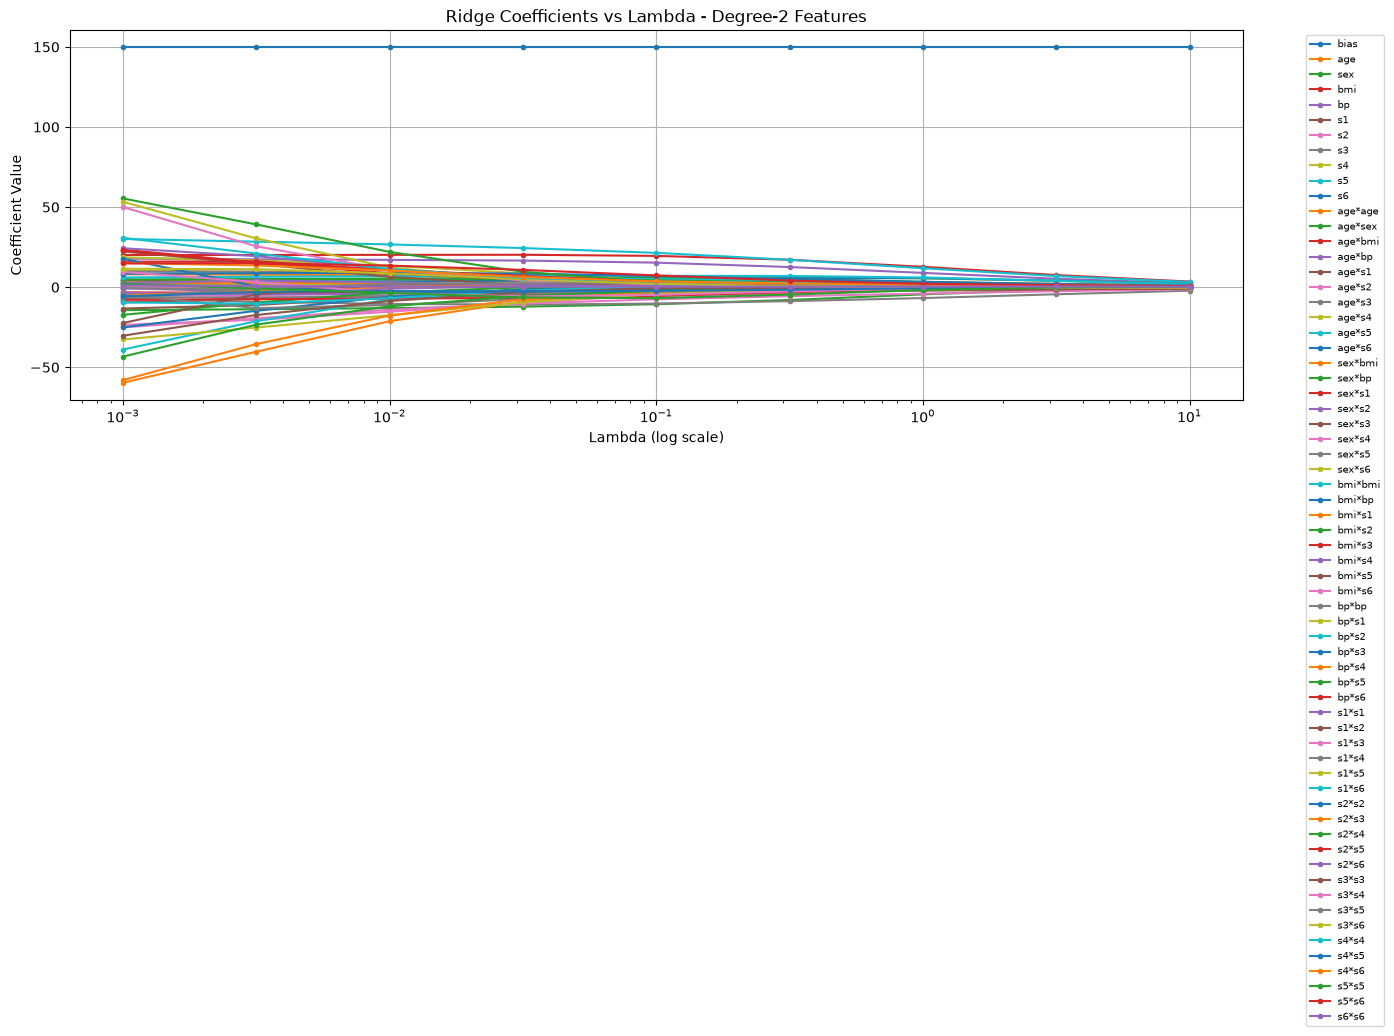

In [45]:
base_names = list(datasets["Diabetes"]["feature_names"])

poly_names = base_names.copy()

for i in range(len(base_names)):
    for j in range(i, len(base_names)):

        if i == 1 and j == 1:
            continue

        poly_names.append(f"{base_names[i]}*{base_names[j]}")

feature_names_poly = ["bias"] + poly_names

# Plot coefficients vs lambda

positive_lambdas = lambdas[lambdas > 0]

plt.figure(figsize=(14, 8))

for i, name in enumerate(feature_names_poly):
    coefficients = [
        ridge_poly_results[lam]["weights"][i]
        for lam in positive_lambdas
    ]

    plt.plot(positive_lambdas, coefficients, marker='o',
             markersize=3, label=name)

plt.xscale("log")
plt.xlabel("Lambda (log scale)")
plt.ylabel("Coefficient Value")
plt.title("Ridge Coefficients vs Lambda - Degree-2 Features")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=7)
plt.grid(True)
plt.tight_layout()
plt.show()

### Plot Validation RMSE vs Lambda for degree-2 features

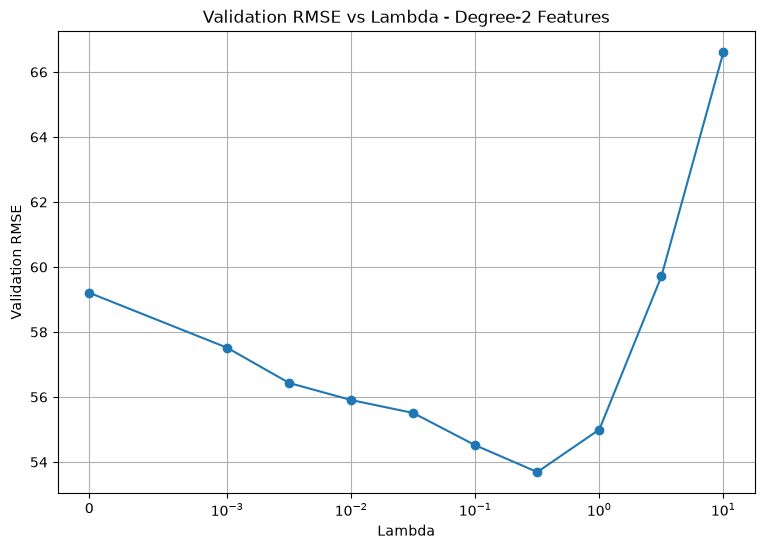

In [46]:
poly_val_errors = [
    ridge_poly_results[lam]["val_rmse"]
    for lam in lambdas
]

plt.figure(figsize=(9, 6))

plt.plot(lambdas, poly_val_errors, marker='o')

plt.xscale("symlog", linthresh=0.001)
plt.xlabel("Lambda")
plt.ylabel("Validation RMSE")
plt.title("Validation RMSE vs Lambda - Degree-2 Features")
plt.grid(True)
plt.show()

### Select best lambda using validation RMSE


In [47]:
best_lambda_poly = min(
    ridge_poly_results,
    key=lambda lam: ridge_poly_results[lam]["val_rmse"]
)

best_result = ridge_poly_results[best_lambda_poly]

test_rmse_lambda0 = ridge_poly_results[0.0]["test_rmse"]
test_rmse_best = best_result["test_rmse"]

print("Best Lambda:", best_lambda_poly)
print("Best Validation RMSE:", best_result["val_rmse"])
print("Test RMSE at best lambda:", test_rmse_best)
print("Test RMSE at lambda = 0:", test_rmse_lambda0)

Best Lambda: 0.31622776601683794
Best Validation RMSE: 53.69171445031375
Test RMSE at best lambda: 52.264723336991295
Test RMSE at lambda = 0: 62.133373395428386


### Ridge Batch Gradient Descent


In [48]:
def ridge_batch_gd(X, y, lam, learning_rate=0.4, epochs=3000):

    X_b = add_bias(X)
    N = len(y)

    w = np.zeros(X_b.shape[1])

    I0 = np.eye(X_b.shape[1])
    I0[0, 0] = 0

    for epoch in range(epochs):

        predictions = X_b @ w

        gradient = (
            X_b.T @ (predictions - y) / N
            + lam * (I0 @ w)
        )

        w -= learning_rate * gradient

    return w


# Compare Batch GD with closed-form Ridge

lam = 0.1

w_closed = ridge_closed_form(X_train, y_train, lam)

w_gd = ridge_batch_gd(
    X_train, y_train,
    lam,
    learning_rate=0.4,
    epochs=3000
)

relative_distance = (
    np.linalg.norm(w_gd - w_closed)
    / np.linalg.norm(w_closed)
)

print("Relative distance:", relative_distance)

assert relative_distance < 1e-6

print("Batch GD verification passed!")

Relative distance: 5.814253687687576e-16
Batch GD verification passed!


In [49]:
from sklearn.linear_model import Ridge

lam = 0.1
N_train = len(y_train)

sk_ridge = Ridge(alpha=lam * N_train)
sk_ridge.fit(X_train, y_train)

sk_weights = np.concatenate((
    [sk_ridge.intercept_],
    sk_ridge.coef_
))

w_closed = ridge_closed_form(X_train, y_train, lam)

print("Maximum weight difference:",
      np.max(np.abs(w_closed - sk_weights)))

assert np.allclose(w_closed, sk_weights, atol=1e-6, rtol=0)

print("Sklearn Ridge verification passed!")

Maximum weight difference: 1.5631940186722204e-13
Sklearn Ridge verification passed!


For the original 10 features, Ridge provides only a small improvement because the number of features is relatively small compared with the number of training samples (264). After degree-2 expansion, the number of features increases to 64 while the number of training samples stays the same, increasing the risk of overfitting and making regularization more beneficial. Ridge reduces the magnitude of the coefficients, which helps control overfitting and improves generalization. The bias must not be penalized because it represents the baseline prediction, and penalizing it would unnecessarily push the intercept toward zero.

In [50]:
import time
import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor

# Prepare data
X_train_bias = add_bias(X_train)
X_test_bias = add_bias(X_test)

N_train = len(y_train)

#helper functions
def calculate_rmse(y_true, y_pred):
    return np.sqrt(np.mean((y_true - y_pred) ** 2))

def relative_distance(w, w_star):
    return np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

results = []

def save_result(name, w, fit_time):
    predictions = X_test_bias @ w

    results.append({
        "Method": name,
        "Test RMSE": calculate_rmse(y_test, predictions),
        "Relative Distance": relative_distance(w, w_star),
        "Fit Time (seconds)": fit_time
    })

#1-normal eqn
start = time.perf_counter()

w_star = np.linalg.solve(
    X_train_bias.T @ X_train_bias,
    X_train_bias.T @ y_train
)

normal_time = time.perf_counter() - start
save_result("Normal Equation", w_star, normal_time)

# 2-Batch Gradient Descent
start = time.perf_counter()

w_batch = np.zeros(X_train_bias.shape[1])

for epoch in range(2000):
    predictions = X_train_bias @ w_batch
    gradient = X_train_bias.T @ (predictions - y_train) / N_train
    w_batch -= 0.5 * gradient

batch_time = time.perf_counter() - start
save_result("Batch GD", w_batch, batch_time)

# 3-Mini-Batch GD
start = time.perf_counter()

w_mini, _, _ = mini_batch_gradient_descent(
    X_train_bias,
    y_train,
    learning_rate=0.01,
    epochs=100,
    batch_size=16
)

mini_time = time.perf_counter() - start
save_result("Mini-Batch GD (B=16)", w_mini, mini_time)

# 4-Ridge from scratch
start = time.perf_counter()

w_ridge = ridge_closed_form(X_train, y_train, 0.1)

ridge_time = time.perf_counter() - start
save_result("Ridge from scratch", w_ridge, ridge_time)

# 5-Scikit-learn Linear Regression
start = time.perf_counter()

sk_linear = LinearRegression()
sk_linear.fit(X_train, y_train)

linear_time = time.perf_counter() - start

w_linear = np.concatenate(([sk_linear.intercept_], sk_linear.coef_))
save_result("Sklearn LinearRegression", w_linear, linear_time)

# 6-Scikit-learn Ridge
start = time.perf_counter()

sk_ridge = Ridge(alpha=0.1 * N_train)
sk_ridge.fit(X_train, y_train)

sk_ridge_time = time.perf_counter() - start

w_sk_ridge = np.concatenate(([sk_ridge.intercept_], sk_ridge.coef_))
save_result("Sklearn Ridge", w_sk_ridge, sk_ridge_time)

# 7-Scikit-learn SGDRegressor
for eta in [0.001, 0.01, 0.1]:

    start = time.perf_counter()

    sk_sgd = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    sk_sgd.fit(X_train, y_train)

    sgd_time = time.perf_counter() - start

    w_sgd = np.concatenate(([sk_sgd.intercept_[0]], sk_sgd.coef_))
    save_result(f"SGDRegressor (eta={eta})", w_sgd, sgd_time)

#show comparison table
comparison_df = pd.DataFrame(results)
display(comparison_df)


,Method,Test RMSE,Relative Distance,Fit Time (seconds)
0,Normal Equation,54.156413,0.000000e+00,0.000682
1,Batch GD,54.156254,1.546262e-04,0.072363
2,Mini-Batch GD (B=16),53.895449,3.421471e-01,0.080728
3,Ridge from scratch,53.708925,3.636136e-01,0.000397
4,Sklearn LinearRegression,54.156413,5.956974e-15,0.003792
5,Sklearn Ridge,53.708925,3.636136e-01,0.007148
6,SGDRegressor (eta=0.001),54.088486,4.976050e-02,0.051342
7,SGDRegressor (eta=0.01),54.898061,5.031993e-02,0.032099
8,SGDRegressor (eta=0.1),71.449348,3.949685e-01,0.031940


The Normal Equation and Scikit-learn LinearRegression produce almost identical results, while the Ridge implementation from scratch and Scikit-learn Ridge also agree closely. Gradient Descent gives a result very close to the optimal solution, whereas Mini-batch Gradient Descent and SGDRegressor show some differences because they use iterative updates and may not fully converge to the same weights. The SGDRegressor with a learning rate of 0.1 performs significantly worse than with 0.001 because the larger learning rate causes unstable updates.

## Part C — Logistic regression

In [51]:
cancer_split = prepared_datasets["Breast Cancer"]

X_train_c = cancer_split["X_train"]
X_val_c = cancer_split["X_val"]
X_test_c = cancer_split["X_test"]

y_train_c = cancer_split["y_train"]
y_val_c = cancer_split["y_val"]
y_test_c = cancer_split["y_test"]

print("Training:", X_train_c.shape)
print("Validation:", X_val_c.shape)
print("Testing:", X_test_c.shape)

print("Classes:", np.unique(y_train_c))

Training: (341, 30)
Validation: (114, 30)
Testing: (114, 30)
Classes: [0 1]


### PART C.1:Derivation and stable implementation
The predicted probability is:

[
p=\sigma(z), \qquad z=\tilde Xw
]

where the sigmoid function is:

[
\sigma(z)=\frac{1}{1+e^{-z}}
]

The Binary Cross-Entropy loss for one sample is:

[
\ell=-y\log(p)-(1-y)\log(1-p)
]

2. Gradient Derivation

Using the chain rule:

[
\frac{dp}{dz}=p(1-p)
]

\left(-\frac{y}{p}+\frac{1-y}{1-p}\right)p(1-p)
]

After simplification:

[
\frac{\partial \ell}{\partial z}=p-y
]

Therefore, the gradient for all samples is:

[
\nabla J(w)=\frac{1}{N}\tilde X^T(p-y)
]

With L2 regularization:

[
\nabla J(w)=\frac{1}{N}\tilde X^T(p-y)+\lambda[0,w_{1:}]
]

The bias term is not regularized.

3. Stable Loss Function

The loss can also be written as:

[
\ell(z,y)=\log(1+e^z)-yz
]

We use np.logaddexp(0,z) to calculate it safely and avoid numerical overflow.


In [84]:
def sigmoid(z):
    z = np.asarray(z, dtype=float)

    result = np.empty_like(z)

    positive = z >= 0
    negative = ~positive

    result[positive] = 1 / (1 + np.exp(-z[positive]))

    exp_z = np.exp(z[negative])
    result[negative] = exp_z / (1 + exp_z)

    return result


print(sigmoid(np.array([-10, 0, 10])))

[0.000045 0.5      0.999955]


In [85]:
def logistic_loss(X, y, w, lam=0.0):
    X_b = add_bias(X)
    z = X_b @ w

    data_loss = np.mean(np.logaddexp(0, z) - y * z)

    reg_loss = (lam / 2) * np.sum(w[1:] ** 2)

    return data_loss + reg_loss

In [86]:
def logistic_gradient(X, y, w, lam=0.0):
    X_b = add_bias(X)
    N = len(y)

    p = sigmoid(X_b @ w)

    reg = np.zeros_like(w)
    reg[1:] = lam * w[1:]

    return X_b.T @ (p - y) / N + reg

In [87]:
z_extreme = np.array([-800.0, 800.0])
y_extreme = np.array([0.0, 1.0])

with np.errstate(over='ignore', divide='ignore', invalid='ignore'):
    p_naive = 1 / (1 + np.exp(-z_extreme))

    naive_loss = -np.mean(
        y_extreme * np.log(p_naive)
        + (1-y_extreme) * np.log(1-p_naive)
    )

stable_p = sigmoid(z_extreme)

stable_loss = np.mean(
    np.logaddexp(0, z_extreme) - y_extreme * z_extreme
)

print("Naive probabilities:", p_naive)
print("Naive loss:", naive_loss)
print("Stable probabilities:", stable_p)
print("Stable loss:", stable_loss)

Naive probabilities: [0. 1.]
Naive loss: nan
Stable probabilities: [0. 1.]
Stable loss: 0.0


In [88]:
# Gradient check for logistic regression with regularization
rng = np.random.default_rng(42)

X_small = rng.normal(size=(5, 3))
y_small = np.array([0, 1, 0, 1, 1])
w_small = rng.normal(size=4)

lam = 0.1

def loss_check(w):
    return logistic_loss(X_small, y_small, w, lam)

def gradient_check(w):
    return logistic_gradient(X_small, y_small, w, lam)

error = grad_check(loss_check, gradient_check, w_small)

print("Gradient check error:", error)

assert error < 1e-6

Gradient check error: 3.476467873382304e-11


### PART C.2:Training and regularization

In [80]:

def logistic_gradient_descent(
    X, y, X_val, y_val,
    learning_rate=0.5,
    epochs=3000,
    lam=0.0
):
    X_b = add_bias(X)
    X_val_b = add_bias(X_val)

    w = np.zeros(X_b.shape[1])

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Update weights
        gradient = logistic_gradient(X, y, w, lam)
        w -= learning_rate * gradient

        # Training metrics
        train_losses.append(logistic_loss(X, y, w, lam))

        p_train = sigmoid(X_b @ w)
        train_pred = (p_train >= 0.5).astype(int)
        train_accuracies.append(accuracy_score(y, train_pred))

        # Validation metrics
        val_losses.append(logistic_loss(X_val, y_val, w, lam))

        p_val = sigmoid(X_val_b @ w)
        val_pred = (p_val >= 0.5).astype(int)
        val_accuracies.append(accuracy_score(y_val, val_pred))

    return w, train_losses, val_losses, train_accuracies, val_accuracies


Training for different lambda values

In [81]:

lambdas = [0, 1e-3, 1e-2, 1e-1, 1]

results = {}

for lam in lambdas:

    w, train_loss, val_loss, train_acc, val_acc = logistic_gradient_descent(
        X_train_c, y_train_c,
        X_val_c, y_val_c,
        learning_rate=0.5,
        epochs=3000,
        lam=lam
    )

    results[lam] = {
        "weights": w,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "train_acc": train_acc,
        "val_acc": val_acc
    }

print("Training completed for all lambda values.")


Training completed for all lambda values.


In [91]:

rows = []

for lam in lambdas:
    r = results[lam]
    w = r["weights"]

    rows.append({
        "Lambda": lam,
        "Train Accuracy": r["train_acc"][-1],
        "Validation Accuracy": r["val_acc"][-1],
        "Validation Loss": r["val_loss"][-1],
        "Weight Norm": np.linalg.norm(w[1:])
    })

results_table = pd.DataFrame(rows)
display(results_table)


,Lambda,Train Accuracy,Validation Accuracy,Validation Loss,Weight Norm
0,0.000,0.994135,0.973684,0.084192,8.132231
1,0.001,0.988270,0.973684,0.086207,5.099928
2,0.010,0.985337,0.973684,0.110010,2.325749
3,0.100,0.973607,0.973684,0.202665,1.105547
4,1.000,0.938416,0.956140,0.389668,0.441485


Best lambda + Test Accuracy

In [92]:
best_lam = min(lambdas, key=lambda lam: results[lam]["val_loss"][-1])

best = results[best_lam]
w_best = best["weights"]

p_test = sigmoid(add_bias(X_test_c) @ w_best)
test_pred = (p_test >= 0.5).astype(int)

print("Best Lambda:", best_lam)
print("Test Accuracy:", accuracy_score(y_test_c, test_pred))

Best Lambda: 0
Test Accuracy: 0.9736842105263158


Plot Training and Validation Loss & Accuracy

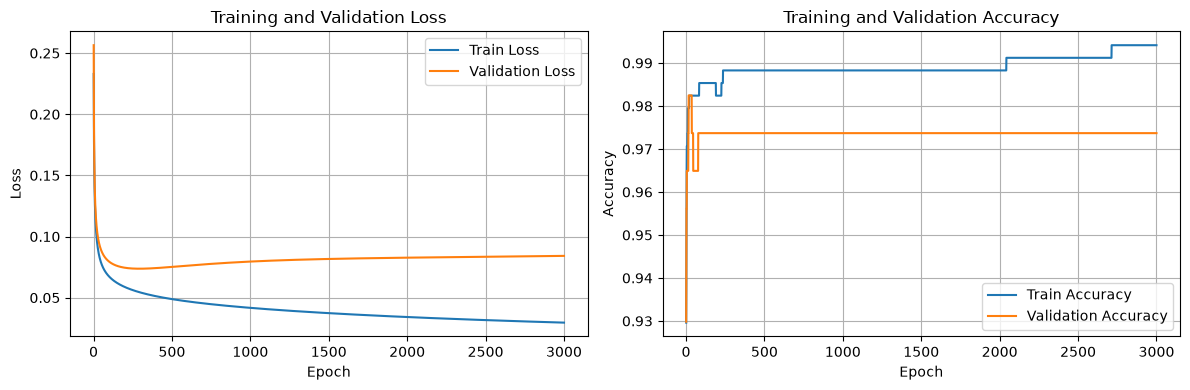

In [89]:
import matplotlib.pyplot as plt

epochs_axis = np.arange(1, 3001)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss
axes[0].plot(epochs_axis, best["train_loss"], label="Train Loss")
axes[0].plot(epochs_axis, best["val_loss"], label="Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(epochs_axis, best["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_axis, best["val_acc"], label="Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Learning Rate Experiment

In [90]:
learning_rates = [0.01, 0.1, 1, 5, 20]

lr_results = []

for eta in learning_rates:

    w, train_loss, val_loss, train_acc, val_acc = logistic_gradient_descent(
        X_train_c, y_train_c,
        X_val_c, y_val_c,
        learning_rate=eta,
        epochs=1000,
        lam=0.01
    )

    lr_results.append({
        "Learning Rate": eta,
        "Final Train Loss": train_loss[-1]
    })

lr_table = pd.DataFrame(lr_results)

display(lr_table)

,Learning Rate,Final Train Loss
0,0.01,0.116289
1,0.10,0.098311
2,1.00,0.098112
3,5.00,0.098112
4,20.00,0.115389


### Observations

- The best regularization parameter was \(\lambda=0\), as it achieved the lowest validation loss.
- Increasing lambda reduced the weight norm and training accuracy.
- The training loss decreased continuously, while the validation loss started increasing slightly after reaching its minimum, indicating mild overfitting.
- A learning rate of 0.01 was too small and resulted in slower convergence.
- Learning rates of 0.1, 1, and 5 achieved lower final training losses, while a learning rate of 20 produced a worse result, indicating unstable training.